# Etapa 1 — Análise Exploratória de Dados (EDA): Telco Customer Churn

Este notebook investiga o dataset público **Telco Customer Churn (IBM)** para embasar decisões de
limpeza, pré-processamento, engenharia de features, escolha de métricas e formulação do **ML Canvas**.

Toda a lógica reutilizável de carga e limpeza reside em [`src/churn/data.py`](../src/churn/data.py)
e as constantes em [`src/churn/config.py`](../src/churn/config.py), garantindo consistência
entre exploração, treino e API em produção.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from churn.config import (
    CATEGORICAL_FEATURES,
    FIGURES_DIR,
    ID_COLUMN,
    NUMERIC_FEATURES,
    RAW_DATA_FILE,
    TARGET,
)
from churn.data import clean, load_raw

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"Dataset bruto: {RAW_DATA_FILE}")
print(f"Diretório de figuras: {FIGURES_DIR}")


Dataset bruto: G:\Meu Drive\03.git_desktop\tech_challenge_churn\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv
Diretório de figuras: G:\Meu Drive\03.git_desktop\tech_challenge_churn\reports\figures


## 1. Volume, Estrutura e Auditoria de Qualidade do Dataset Bruto

Carregamos o CSV imutável via `load_raw()` sem alterar o arquivo original em `data/raw/`.
Verificamos dimensões, tipos de dados, valores ausentes, valores em branco ocultos e duplicidades.


In [2]:
raw_df = load_raw(RAW_DATA_FILE)
print(f"Dimensões do dataset bruto: {raw_df.shape[0]:,} linhas x {raw_df.shape[1]} colunas")
print(f"Coluna de ID: {ID_COLUMN} | Target: {TARGET}")
print(f"IDs duplicados: {raw_df[ID_COLUMN].duplicated().sum()} | Linhas duplicadas: {raw_df.duplicated().sum()}")
print(f"Valores NaN literais no bruto: {int(raw_df.isna().sum().sum())}")

display(raw_df.head(3))

dtype_summary = pd.DataFrame({
    "dtype_bruto": raw_df.dtypes.astype(str),
    "valores_unicos": raw_df.nunique(),
    "exemplo": [raw_df[c].iloc[0] for c in raw_df.columns],
})
display(dtype_summary)


Dimensões do dataset bruto: 7,043 linhas x 21 colunas
Coluna de ID: customerID | Target: Churn
IDs duplicados: 0 | Linhas duplicadas: 0
Valores NaN literais no bruto: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


,dtype_bruto,valores_unicos,exemplo
customerID,str,7043,7590-VHVEG
gender,str,2,Female
SeniorCitizen,int64,2,0
Partner,str,2,Yes
Dependents,str,2,No
tenure,int64,73,1
PhoneService,str,2,No
MultipleLines,str,3,No phone service
InternetService,str,3,DSL
OnlineSecurity,str,3,No


### Diagnóstico de `TotalCharges` e `SeniorCitizen`

Mesmo sem `NaN` literais no CSV, `TotalCharges` é lida como `object`/`str` porque clientes
recém-chegados possuem espaços em branco (`" "`). Vamos inspecionar exatamente esses registros
antes de aplicar `clean()`.


In [3]:
blank_mask = raw_df["TotalCharges"].astype(str).str.strip() == ""
print(f"Registros com TotalCharges em branco: {int(blank_mask.sum())}")
display(
    raw_df.loc[blank_mask, ["customerID", "tenure", "Contract", "MonthlyCharges", "TotalCharges", "Churn"]]
)
print("Distribuição de tenure entre os 11 em branco:", raw_df.loc[blank_mask, "tenure"].value_counts().to_dict())
print("Distribuição de Churn entre os 11 em branco:", raw_df.loc[blank_mask, "Churn"].value_counts().to_dict())


Registros com TotalCharges em branco: 11


,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,Two year,52.55,,No
753,3115-CZMZD,0,Two year,20.25,,No
936,5709-LVOEQ,0,Two year,80.85,,No
1082,4367-NUYAO,0,Two year,25.75,,No
1340,1371-DWPAZ,0,Two year,56.05,,No
3331,7644-OMVMY,0,Two year,19.85,,No
3826,3213-VVOLG,0,Two year,25.35,,No
4380,2520-SGTTA,0,Two year,20.00,,No
5218,2923-ARZLG,0,One year,19.70,,No
6670,4075-WKNIU,0,Two year,73.35,,No


Distribuição de tenure entre os 11 em branco: {0: 11}
Distribuição de Churn entre os 11 em branco: {'No': 11}


**Achado crítico de qualidade:**
- Todos os **11** registros com `TotalCharges` em branco possuem **`tenure == 0`** (clientes recém-ativados no mês corrente, ainda sem faturamento acumulado) e `Churn == "No"`.
- A função determinística `clean(raw_df)` converte `TotalCharges` para `float64` (`errors="coerce"` -> 11 `NaN`), converte `SeniorCitizen` (`0/1`) em `"No"/"Yes"` para padronização categórica, mapeia `Churn` para `0/1` e remove `customerID`.
- Os 11 `NaN` de `TotalCharges` serão preenchidos exclusivamente via `SimpleImputer(strategy="median")` ajustado **apenas no conjunto de treino** dentro do `Pipeline` de modelagem (zero *data leakage*).


In [4]:
df = clean(raw_df)
print(f"Dimensões após clean(): {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print("SeniorCitizen após clean():", df["SeniorCitizen"].value_counts().to_dict())
print("Churn após clean():", df["Churn"].value_counts().to_dict())
print("NaNs por coluna após clean() (apenas TotalCharges):", df.isna().sum()[df.isna().sum() > 0].to_dict())


Dimensões após clean(): 7,043 linhas x 20 colunas
SeniorCitizen após clean(): {'No': 5901, 'Yes': 1142}
Churn após clean(): {0: 5174, 1: 1869}
NaNs por coluna após clean() (apenas TotalCharges): {'TotalCharges': 11}


## 2. Distribuição do Target (`Churn`) e Impacto Financeiro Bruto

Avaliamos o desbalanceamento da variável alvo e a receita mensal associada aos clientes que cancelaram.


,count,mean,median,sum
No (0),5174,61.27,64.43,316985.75
Yes (1),1869,74.44,79.65,139130.85


Taxa global de Churn: 26.54% (1,869 de 7,043 clientes). Receita mensal perdida diretamente pelos churners na base: $139,130.85/mês.


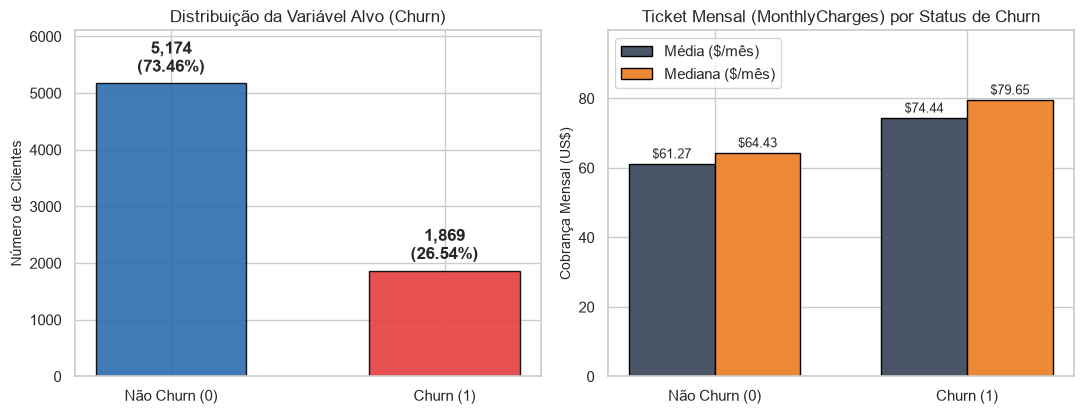

In [5]:
churn_counts = df[TARGET].value_counts().sort_index()
churn_pct = df[TARGET].value_counts(normalize=True).sort_index() * 100
rev_by_churn = df.groupby(TARGET)["MonthlyCharges"].agg(["count", "mean", "median", "sum"])
rev_by_churn.index = ["No (0)", "Yes (1)"]
display(rev_by_churn.round(2))

print(
    f"Taxa global de Churn: {churn_pct[1]:.2f}% ({churn_counts[1]:,} de {len(df):,} clientes). "
    f"Receita mensal perdida diretamente pelos churners na base: ${df.loc[df[TARGET] == 1, 'MonthlyCharges'].sum():,.2f}/mês."
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

labels = ["Não Churn (0)", "Churn (1)"]
colors = ["#2b6cb0", "#e53e3e"]
bars = axes[0].bar(labels, churn_counts.values, color=colors, width=0.55, edgecolor="black", alpha=0.9)
axes[0].set_title("Distribuição da Variável Alvo (Churn)")
axes[0].set_ylabel("Número de Clientes")
axes[0].set_ylim(0, churn_counts.max() * 1.18)
for bar, count, pct in zip(bars, churn_counts.values, churn_pct.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 120,
        f"{count:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

mean_charges = [df.loc[df[TARGET] == 0, "MonthlyCharges"].mean(), df.loc[df[TARGET] == 1, "MonthlyCharges"].mean()]
med_charges = [df.loc[df[TARGET] == 0, "MonthlyCharges"].median(), df.loc[df[TARGET] == 1, "MonthlyCharges"].median()]
x = np.arange(2)
w = 0.34
b1 = axes[1].bar(x - w / 2, mean_charges, width=w, label="Média ($/mês)", color="#4a5568", edgecolor="black")
b2 = axes[1].bar(x + w / 2, med_charges, width=w, label="Mediana ($/mês)", color="#ed8936", edgecolor="black")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylabel("Cobrança Mensal (US$)")
axes[1].set_title("Ticket Mensal (MonthlyCharges) por Status de Churn")
axes[1].set_ylim(0, max(med_charges) * 1.25)
axes[1].legend(frameon=True)
for b in [*b1, *b2]:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f"${b.get_height():.2f}", ha="center", fontsize=9)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 3. Distribuições das Features Numéricas (`tenure`, `MonthlyCharges`, `TotalCharges`)

Inspecionamos estatísticas descritivas e densidades separadas por classe `Churn`.


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7032.0,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80


tenure               MonthlyCharges               TotalCharges           \
        mean median    std           mean median    std         mean   median   
Churn                                                                           
0      37.57   38.0  24.11          61.27  64.43  31.09      2555.34  1683.60   
1      17.98   10.0  19.53          74.44  79.65  24.67      1531.80   703.55   

                
           std  
Churn           
0      2329.46  
1      1890.82

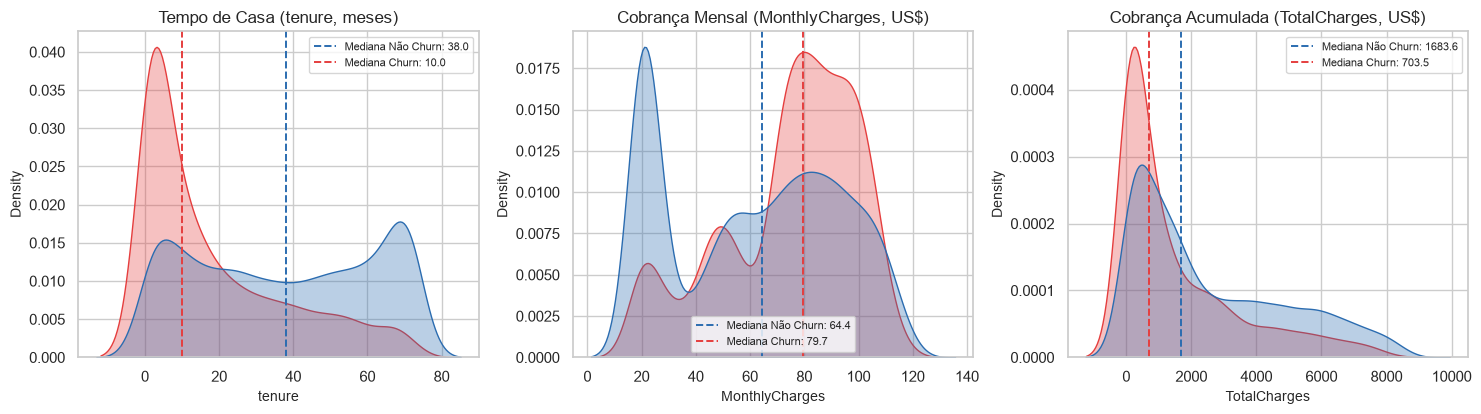

In [6]:
display(df[NUMERIC_FEATURES].describe().T.round(2))
display(df.groupby(TARGET)[NUMERIC_FEATURES].agg(["mean", "median", "std"]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
num_titles = {
    "tenure": "Tempo de Casa (tenure, meses)",
    "MonthlyCharges": "Cobrança Mensal (MonthlyCharges, US$)",
    "TotalCharges": "Cobrança Acumulada (TotalCharges, US$)",
}

for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.kdeplot(data=df, x=col, hue=TARGET, common_norm=False, fill=True, alpha=0.32,
                palette={0: "#2b6cb0", 1: "#e53e3e"}, ax=ax)
    med0 = df.loc[df[TARGET] == 0, col].median()
    med1 = df.loc[df[TARGET] == 1, col].median()
    ax.axvline(med0, color="#2b6cb0", linestyle="--", linewidth=1.4, label=f"Mediana Não Churn: {med0:.1f}")
    ax.axvline(med1, color="#e53e3e", linestyle="--", linewidth=1.4, label=f"Mediana Churn: {med1:.1f}")
    ax.set_title(num_titles[col])
    ax.set_xlabel(col)
    ax.legend(fontsize=8, frameon=True)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_numeric_distributions.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


**Observações nas variáveis numéricas:**
- **Churn precoce (`tenure`):** a mediana de permanência de quem cancela é de apenas **10 meses** (média **17,98**), contra **38 meses** (média **37,57**) para quem permanece.
- **Sensibilidade a preço (`MonthlyCharges`):** quem cancela paga em média **$74,44/mês** (mediana **$79,65**) versus **$61,27/mês** (mediana **$64,43**) entre não-churners.
- **`TotalCharges`** reflete o produto aproximado `tenure × MonthlyCharges`; por isso é menor entre churners (mediana **$703,55** vs **$1.683,60**), gerando alta colinearidade com `tenure`.


## 4. Taxa de Churn por Variáveis Categóricas-Chave

Analisamos os principais atributos de contrato, serviço de internet, pagamento, suporte, segurança,
faixa etária (`SeniorCitizen`) e gênero (`gender`), comparando contra a média global de **26,54%**.


,feature,categoria,clientes,churn_pct
0,Contract,Month-to-month,3875,42.71
1,Contract,One year,1473,11.27
2,Contract,Two year,1695,2.83
3,InternetService,DSL,2421,18.96
4,InternetService,Fiber optic,3096,41.89
5,InternetService,No,1526,7.40
6,PaymentMethod,Bank transfer (automatic),1544,16.71
7,PaymentMethod,Credit card (automatic),1522,15.24
8,PaymentMethod,Electronic check,2365,45.29
9,PaymentMethod,Mailed check,1612,19.11


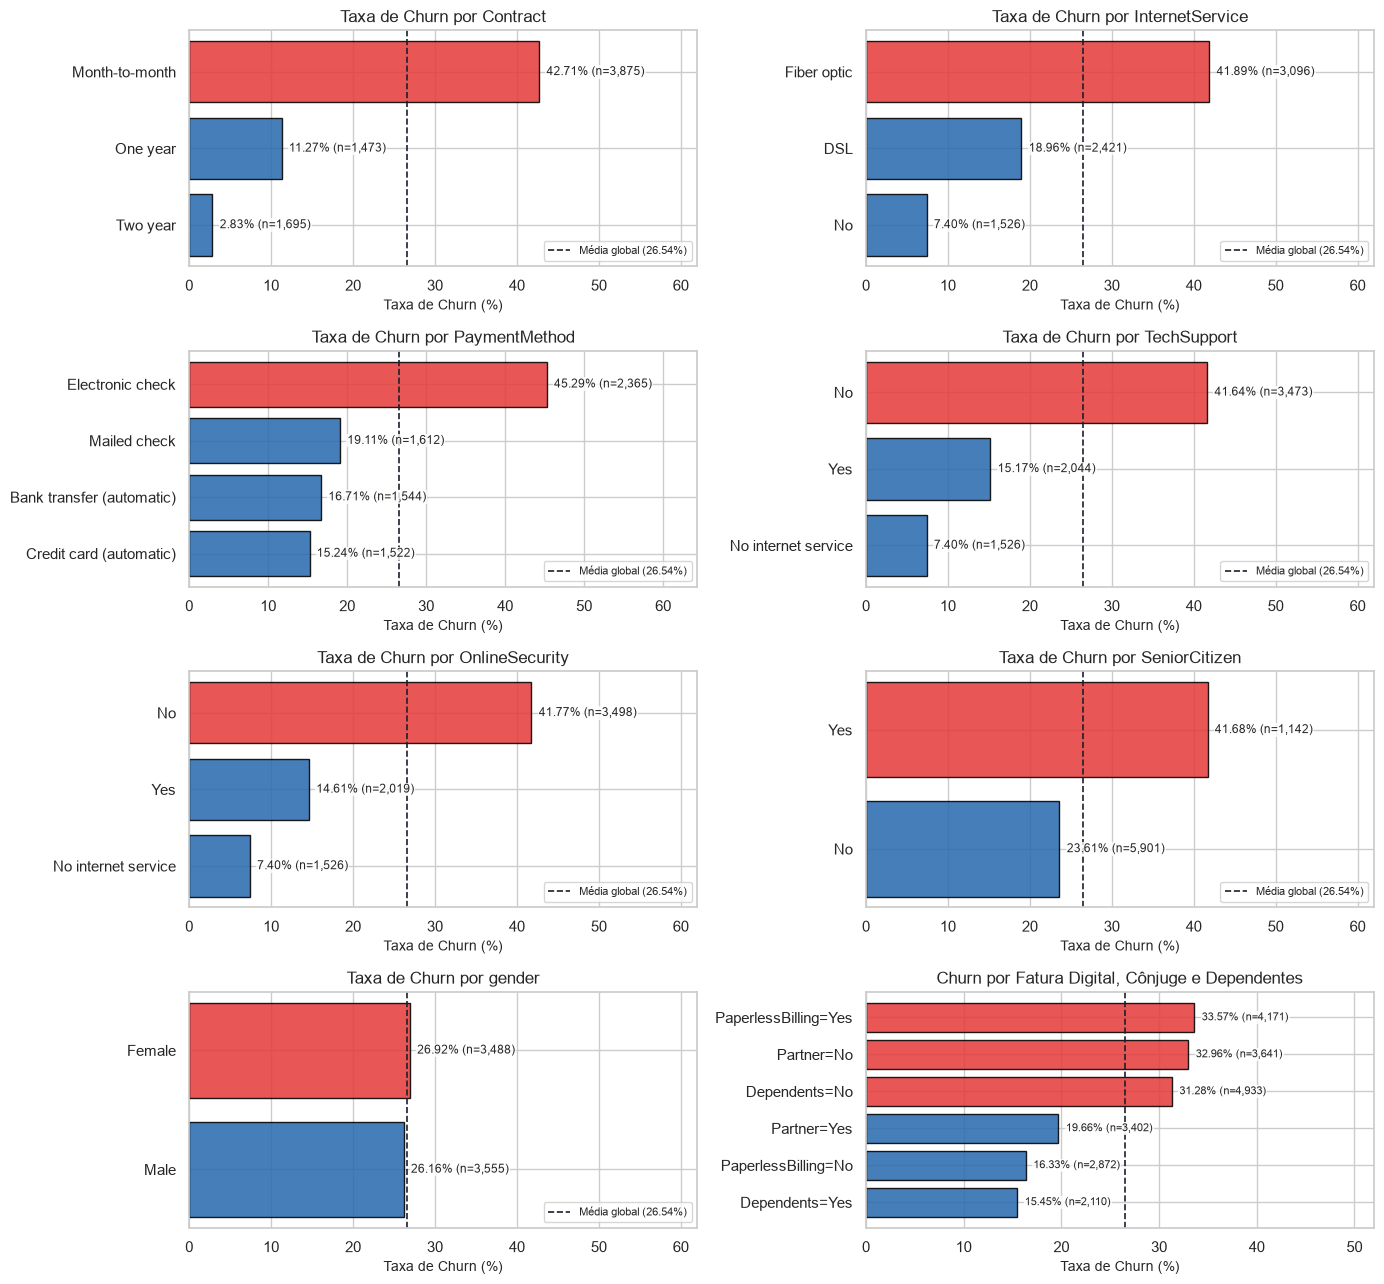

In [7]:
key_cats = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "SeniorCitizen",
    "gender",
]

global_rate = df[TARGET].mean() * 100
summary_rows = []
for col in key_cats:
    grp = df.groupby(col)[TARGET].agg(["count", "mean"]).reset_index()
    for _, row in grp.iterrows():
        summary_rows.append({
            "feature": col,
            "categoria": row[col],
            "clientes": int(row["count"]),
            "churn_pct": round(float(row["mean"]) * 100, 2),
        })
cat_summary_df = pd.DataFrame(summary_rows)
display(cat_summary_df)

fig, axes = plt.subplots(4, 2, figsize=(14, 13))
axes_flat = axes.flatten()

for ax, col in zip(axes_flat, key_cats):
    sub = cat_summary_df[cat_summary_df["feature"] == col].sort_values("churn_pct", ascending=True)
    bar_colors = ["#e53e3e" if v >= global_rate else "#2b6cb0" for v in sub["churn_pct"]]
    bars = ax.barh(sub["categoria"].astype(str), sub["churn_pct"], color=bar_colors, edgecolor="black", alpha=0.88)
    ax.axvline(global_rate, color="#1a202c", linestyle="--", linewidth=1.2, label=f"Média global ({global_rate:.2f}%)")
    ax.set_xlim(0, max(sub["churn_pct"].max() * 1.42, 62))
    ax.set_title(f"Taxa de Churn por {col}")
    ax.set_xlabel("Taxa de Churn (%)")
    for bar, (_, r) in zip(bars, sub.iterrows()):
        ax.text(
            bar.get_width() + 0.9,
            bar.get_y() + bar.get_height() / 2,
            f"{r['churn_pct']:.2f}% (n={r['clientes']:,})",
            va="center",
            fontsize=8.5,
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=0.8),
        )
    ax.legend(loc="lower right", fontsize=8)

# Último painel: features complementares (PaperlessBilling, Partner, Dependents)
extra_rows = []
for col in ["PaperlessBilling", "Partner", "Dependents"]:
    for cat_val, grp_val in df.groupby(col)[TARGET].agg(["count", "mean"]).iterrows():
        extra_rows.append({
            "label": f"{col}={cat_val}",
            "clientes": int(grp_val["count"]),
            "churn_pct": float(grp_val["mean"]) * 100,
        })
extra_df = pd.DataFrame(extra_rows).sort_values("churn_pct", ascending=True)
ax_extra = axes_flat[-1]
bars = ax_extra.barh(
    extra_df["label"],
    extra_df["churn_pct"],
    color=["#e53e3e" if v >= global_rate else "#2b6cb0" for v in extra_df["churn_pct"]],
    edgecolor="black",
    alpha=0.88,
)
ax_extra.axvline(global_rate, color="#1a202c", linestyle="--", linewidth=1.2)
ax_extra.set_xlim(0, 52)
ax_extra.set_title("Churn por Fatura Digital, Cônjuge e Dependentes")
ax_extra.set_xlabel("Taxa de Churn (%)")
for bar, (_, r) in zip(bars, extra_df.iterrows()):
    ax_extra.text(
        bar.get_width() + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{r['churn_pct']:.2f}% (n={r['clientes']:,})",
        va="center",
        fontsize=8,
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=0.8),
    )

fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_categorical_churn_rates.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 5. Correlações e Síntese de Negócio para Modelagem

Calculamos a matriz de correlação das variáveis numéricas com `Churn` e resumimos os achados
acionáveis que alimentam o **ML Canvas** e a escolha de famílias de modelos.


In [8]:
corr_df = df[[*NUMERIC_FEATURES, TARGET]].corr(numeric_only=True)
display(corr_df.round(4))

print(f"Correlação tenure vs TotalCharges: {corr_df.loc['tenure', 'TotalCharges']:.4f}")
print(f"Correlação tenure vs Churn: {corr_df.loc['tenure', TARGET]:.4f}")
print(f"Correlação MonthlyCharges vs Churn: {corr_df.loc['MonthlyCharges', TARGET]:.4f}")
print(f"Total de features usadas na modelagem (sem customerID): {len(NUMERIC_FEATURES) + len(CATEGORICAL_FEATURES)}")


,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.0000,0.2479,0.8259,-0.3522
MonthlyCharges,0.2479,1.0000,0.6511,0.1934
TotalCharges,0.8259,0.6511,1.0000,-0.1995
Churn,-0.3522,0.1934,-0.1995,1.0000


Correlação tenure vs TotalCharges: 0.8259
Correlação tenure vs Churn: -0.3522
Correlação MonthlyCharges vs Churn: 0.1934
Total de features usadas na modelagem (sem customerID): 19


### Principais Insights da EDA

1. **Alavanca Contratual (`Contract`):** clientes com contrato mensal (*Month-to-month*) concentram **42,71%** de churn (`n=3.875`), contra **11,27%** no contrato de 1 ano e apenas **2,83%** no contrato de 2 anos — uma diferença superior a **15x**.
2. **Fibra Óptica e Serviços Agregados:** usuários de *Fiber optic* apresentam **41,89%** de churn (provavelmente associado a mensalidades mais elevadas e expectativa de qualidade), enquanto ausência de `TechSupport` (**41,64%**) ou `OnlineSecurity` (**41,77%**) quase triplica o risco frente a quem possui esses serviços (~**15%**).
3. **Meio de Pagamento (`PaymentMethod`):** *Electronic check* lidera isolado com **45,29%** de churn, frente a ~**15–19%** nos meios automáticos ou cheque enviado.
4. **Perfil Demográfico e Equidade (*Fairness*):** `gender` apresenta diferença mínima (**26,92%** feminino vs **26,16%** masculino), enquanto `SeniorCitizen == "Yes"` atinge **41,68%** vs **23,61%**, exigindo monitoramento futuro de vieses em produção.
5. **Implicação para Métricas:** com **26,54%** de positivos e alta assimetria de valor (perder um cliente custa muito mais do que oferecer retenção a um cliente fiel), **Acurácia isolada engana** e devemos calibrar limiares por **Receita Retida Líquida** e **Recall/F1**.
